<a href="https://colab.research.google.com/github/harsha-vardhann-reddy/Deep-Learning-Session/blob/main/Skill-1_DLAC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q ultralytics opencv-python matplotlib pandas fastapi

In [2]:
import os
import cv2
import json
import time
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from collections import Counter
from ultralytics import YOLO
from google.colab import files
from IPython.display import display

DEVICE = 0 if torch.cuda.is_available() else "cpu"

print("VISIONPORT INITIALISED")
print("----------------------")
print("PyTorch:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())
print("Execution Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
VISIONPORT INITIALISED
----------------------
PyTorch: 2.14.1+cpu
CUDA Available: False
Execution Device: cpu
Running on CPU


In [3]:
MODEL_NAME = "yolov8n.pt"

model = YOLO(MODEL_NAME)

print("VisionPort Model Loaded")
print("Model:", MODEL_NAME)
print("Number of classes:", len(model.names))
print("Classes:", model.names)

VisionPort Model Loaded
Model: yolov8n.pt
Number of classes: 80
Classes: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 62: 'tv', 63: 'laptop',

In [4]:
classes = model.names

coco_categories = pd.DataFrame([
    {"Class ID": class_id, "Category": name}
    for class_id, name in classes.items()
])

display(coco_categories)

traffic_classes = [
    "person",
    "bicycle",
    "car",
    "motorcycle",
    "bus",
    "train",
    "truck",
    "traffic light",
    "stop sign"
]

traffic_categories = coco_categories[
    coco_categories["Category"].isin(traffic_classes)
]

print("Traffic-related categories:")
display(traffic_categories)

,Class ID,Category
0,0,person
1,1,bicycle
2,2,car
3,3,motorcycle
4,4,airplane
...,...,...
75,75,vase
76,76,scissors
77,77,teddy bear
78,78,hair drier


Traffic-related categories:


,Class ID,Category
0,0,person
1,1,bicycle
2,2,car
3,3,motorcycle
5,5,bus
6,6,train
7,7,truck
9,9,traffic light
11,11,stop sign


In [5]:
print("VISIONPORT IMAGE UPLOAD")

uploaded = files.upload()

image_paths = []

for filename, content in uploaded.items():
    path = Path(filename)

    with open(path, "wb") as f:
        f.write(content)

    image_paths.append(str(path))

print("\nUploaded images:", len(image_paths))

for path in image_paths:
    print(path)

VISIONPORT IMAGE UPLOAD


Saving DL.jpg to DL.jpg

Uploaded images: 1
DL.jpg


In [6]:
def visionport_detect(image_path):

    timings = {}

    total_start = time.perf_counter()

    # Stage 1: Image input and decoding
    start = time.perf_counter()

    image = cv2.imread(image_path)

    if image is None:
        raise ValueError(f"Cannot read image: {image_path}")

    timings["Image Decoding"] = (
        time.perf_counter() - start
    ) * 1000

    # Stage 2: Model execution
    start = time.perf_counter()

    results = model.predict(
        source=image,
        imgsz=640,
        conf=0.25,
        device=DEVICE,
        verbose=False
    )

    if DEVICE != "cpu":
        torch.cuda.synchronize()

    timings["Model Execution"] = (
        time.perf_counter() - start
    ) * 1000

    result = results[0]

    # Stage 3: Postprocessing
    start = time.perf_counter()

    detections = []

    for box in result.boxes:

        class_id = int(box.cls.item())

        detections.append({
            "class": model.names[class_id],
            "confidence": round(
                float(box.conf.item()), 4
            ),
            "bounding_box": [
                round(float(x), 2)
                for x in box.xyxy[0].tolist()
            ]
        })

    timings["Postprocessing"] = (
        time.perf_counter() - start
    ) * 1000

    # Stage 4: Generate annotated image
    start = time.perf_counter()

    annotated_image = result.plot()

    timings["Response Preparation"] = (
        time.perf_counter() - start
    ) * 1000

    timings["Total Application Time"] = (
        time.perf_counter() - total_start
    ) * 1000

    response = {
        "image": image_path,
        "model": MODEL_NAME,
        "device": str(DEVICE),
        "total_objects": len(detections),
        "detections": detections,
        "timings_ms": timings
    }

    return response, annotated_image


VISIONPORT INFERENCE RESPONSE
{
    "image": "DL.jpg",
    "model": "yolov8n.pt",
    "device": "cpu",
    "total_objects": 31,
    "detections": [
        {
            "class": "car",
            "confidence": 0.8592,
            "bounding_box": [
                23.51,
                314.14,
                110.02,
                383.78
            ]
        },
        {
            "class": "car",
            "confidence": 0.8534,
            "bounding_box": [
                291.22,
                321.87,
                366.29,
                394.08
            ]
        },
        {
            "class": "car",
            "confidence": 0.8493,
            "bounding_box": [
                143.44,
                311.59,
                231.81,
                394.43
            ]
        },
        {
            "class": "car",
            "confidence": 0.8271,
            "bounding_box": [
                533.96,
                207.58,
                589.67,
            

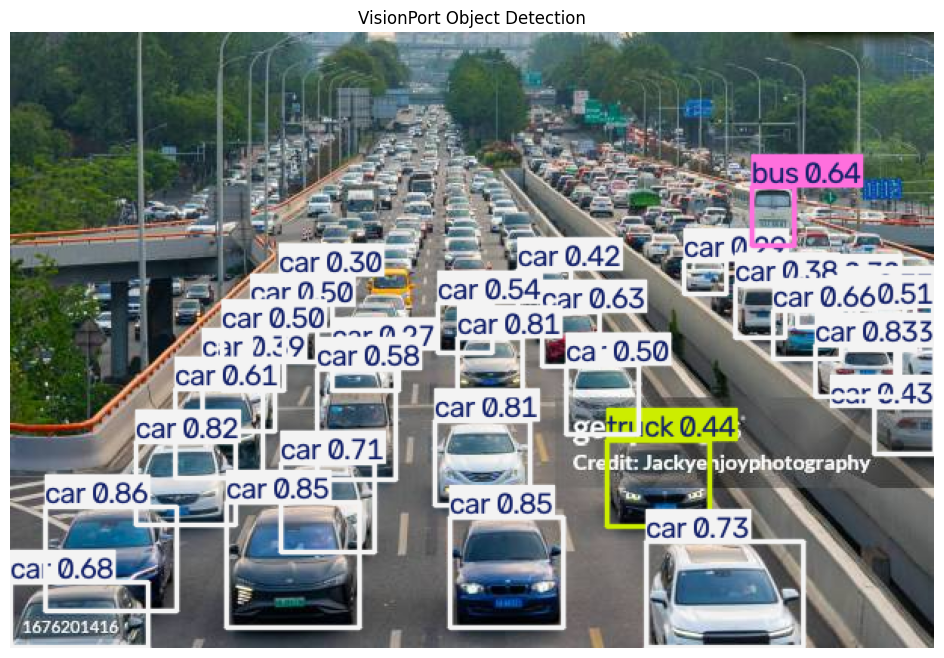

In [7]:
visionport_results = []

for image_path in image_paths:

    response, annotated = visionport_detect(image_path)

    visionport_results.append(response)

    print("\n" + "=" * 55)
    print("VISIONPORT INFERENCE RESPONSE")
    print("=" * 55)

    print(json.dumps(response, indent=4))

    plt.figure(figsize=(14, 8))
    plt.imshow(cv2.cvtColor(
        annotated,
        cv2.COLOR_BGR2RGB
    ))

    plt.title("VisionPort Object Detection")
    plt.axis("off")
    plt.show()

DETECTION AUDIT


,Image,Class,Confidence,Bounding Box
0,DL.jpg,car,0.8592,"[23.51, 314.14, 110.02, 383.78]"
1,DL.jpg,car,0.8534,"[291.22, 321.87, 366.29, 394.08]"
2,DL.jpg,car,0.8493,"[143.44, 311.59, 231.81, 394.43]"
3,DL.jpg,car,0.8271,"[533.96, 207.58, 589.67, 241.27]"
4,DL.jpg,car,0.8209,"[84.0, 271.85, 149.19, 326.2]"
5,DL.jpg,car,0.8147,"[296.21, 202.25, 339.46, 240.08]"
6,DL.jpg,car,0.8084,"[281.71, 257.71, 344.22, 313.57]"
7,DL.jpg,car,0.7330,"[421.75, 337.82, 525.83, 407.29]"
8,DL.jpg,car,0.7137,"[179.43, 285.11, 241.5, 344.63]"
9,DL.jpg,car,0.6776,"[0.12, 364.18, 91.99, 407.74]"



CLASS DISTRIBUTION


,count
Class,
car,29
bus,1
truck,1


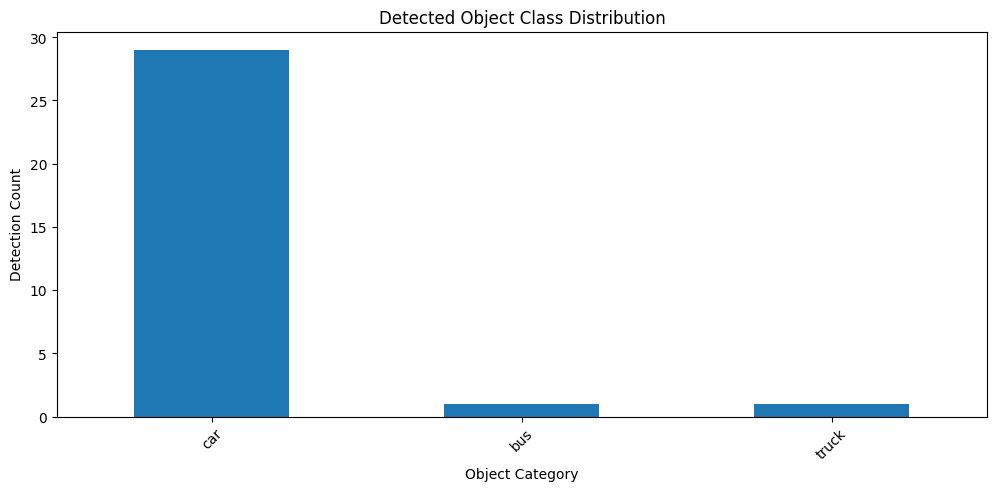


IMAGE QUALITY AUDIT
{'Image': 'DL.jpg', 'Width': 612, 'Height': 408, 'Brightness': 105.04, 'File Size KB': 57.78}


In [8]:
all_detections = []

for response in visionport_results:

    for detection in response["detections"]:

        all_detections.append({
            "Image": response["image"],
            "Class": detection["class"],
            "Confidence": detection["confidence"],
            "Bounding Box": detection["bounding_box"]
        })

df = pd.DataFrame(all_detections)

if not df.empty:

    print("DETECTION AUDIT")
    display(df)

    print("\nCLASS DISTRIBUTION")

    class_counts = df["Class"].value_counts()

    display(class_counts)

    class_counts.plot(
        kind="bar",
        figsize=(12, 5),
        title="Detected Object Class Distribution"
    )

    plt.xlabel("Object Category")
    plt.ylabel("Detection Count")
    plt.xticks(rotation=45)
    plt.show()

    print("\nIMAGE QUALITY AUDIT")

    for path in image_paths:

        image = cv2.imread(path)

        height, width = image.shape[:2]

        brightness = float(np.mean(
            cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        ))

        print({
            "Image": path,
            "Width": width,
            "Height": height,
            "Brightness": round(brightness, 2),
            "File Size KB": round(
                os.path.getsize(path) / 1024, 2
            )
        })

else:
    print("No objects detected.")

In [9]:
request_trace = [
    "HTTP Request / Client Input",
    "FastAPI API Gateway (conceptual)",
    "Image Decoding",
    "Image Preprocessing",
    "Inference Model Execution",
    "GPU / CPU Computation",
    "Bounding Box Postprocessing",
    "JSON Response"
]

print("VISIONPORT REQUEST TRACE")
print("=" * 45)

for i, stage in enumerate(request_trace, 1):
    print(f"{i}. {stage}")

VISIONPORT REQUEST TRACE
1. HTTP Request / Client Input
2. FastAPI API Gateway (conceptual)
3. Image Decoding
4. Image Preprocessing
5. Inference Model Execution
6. GPU / CPU Computation
7. Bounding Box Postprocessing
8. JSON Response


,Image,Stage,Time (ms)
0,DL.jpg,Image Decoding,38.575
1,DL.jpg,Model Execution,7063.564
2,DL.jpg,Postprocessing,15.696
3,DL.jpg,Response Preparation,40.450
4,DL.jpg,Total Application Time,7158.303


AVERAGE EXECUTION TIME


,Time (ms)
Stage,
Total Application Time,7158.303
Model Execution,7063.564
Response Preparation,40.450
Image Decoding,38.575
Postprocessing,15.696


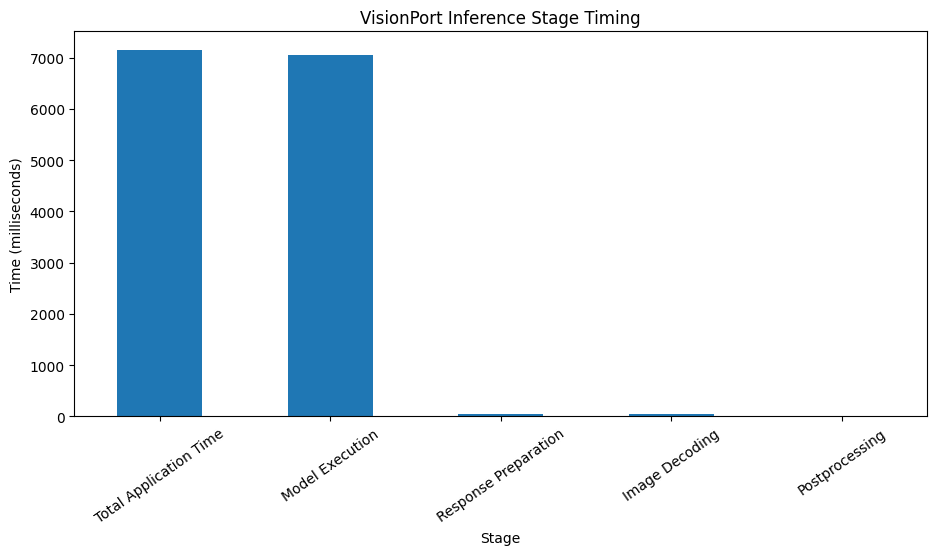

In [10]:
timing_data = []

for response in visionport_results:

    for stage, duration in response["timings_ms"].items():

        timing_data.append({
            "Image": response["image"],
            "Stage": stage,
            "Time (ms)": round(duration, 3)
        })

timing_df = pd.DataFrame(timing_data)

display(timing_df)

average_times = (
    timing_df.groupby("Stage")["Time (ms)"]
    .mean()
    .sort_values(ascending=False)
)

print("AVERAGE EXECUTION TIME")
display(average_times)

average_times.plot(
    kind="bar",
    figsize=(11, 5),
    title="VisionPort Inference Stage Timing"
)

plt.ylabel("Time (milliseconds)")
plt.xticks(rotation=35)
plt.show()

if torch.cuda.is_available():

    print("GPU MEMORY USAGE")

    print(
        "Allocated:",
        round(torch.cuda.memory_allocated() / 1024**2, 2),
        "MB"
    )

    print(
        "Reserved:",
        round(torch.cuda.memory_reserved() / 1024**2, 2),
        "MB"
    )

In [11]:
from fastapi import FastAPI, UploadFile, File, HTTPException
from fastapi.testclient import TestClient

api = FastAPI(title="VisionPort API")

@api.get("/health")
def health():

    return {
        "project": "VisionPort",
        "status": "running",
        "model": MODEL_NAME,
        "device": str(DEVICE)
    }


@api.post("/detect")
async def detect_endpoint(file: UploadFile = File(...)):

    if not file.content_type or not file.content_type.startswith("image/"):
        raise HTTPException(
            status_code=400,
            detail="Please upload an image."
        )

    contents = await file.read()

    image_array = np.frombuffer(
        contents,
        dtype=np.uint8
    )

    image = cv2.imdecode(
        image_array,
        cv2.IMREAD_COLOR
    )

    if image is None:
        raise HTTPException(
            status_code=400,
            detail="Invalid image."
        )

    results = model.predict(
        image,
        imgsz=640,
        conf=0.25,
        device=DEVICE,
        verbose=False
    )

    result = results[0]

    detections = []

    for box in result.boxes:

        class_id = int(box.cls.item())

        detections.append({
            "class": model.names[class_id],
            "confidence": float(box.conf.item()),
            "bounding_box": [
                float(x)
                for x in box.xyxy[0].tolist()
            ]
        })

    return {
        "project": "VisionPort",
        "model": MODEL_NAME,
        "device": str(DEVICE),
        "total_objects": len(detections),
        "detections": detections
    }


client = TestClient(api)

print(client.get("/health").json())

{'project': 'VisionPort', 'status': 'running', 'model': 'yolov8n.pt', 'device': 'cpu'}


In [12]:
with open(image_paths[0], "rb") as f:

    response = client.post(
        "/detect",
        files={
            "file": (
                "traffic.jpg",
                f,
                "image/jpeg"
            )
        }
    )

print("HTTP Status:", response.status_code)

display(response.json())

HTTP Status: 200


{'project': 'VisionPort',
 'model': 'yolov8n.pt',
 'device': 'cpu',
 'total_objects': 31,
 'detections': [{'class': 'car',
   'confidence': 0.8592126369476318,
   'bounding_box': [23.514751434326172,
    314.13623046875,
    110.0171127319336,
    383.7816162109375]},
  {'class': 'car',
   'confidence': 0.8533676862716675,
   'bounding_box': [291.2164611816406,
    321.86688232421875,
    366.2860412597656,
    394.0797119140625]},
  {'class': 'car',
   'confidence': 0.8492584228515625,
   'bounding_box': [143.44338989257812,
    311.5899658203125,
    231.8074493408203,
    394.4288635253906]},
  {'class': 'car',
   'confidence': 0.8270646929740906,
   'bounding_box': [533.9644165039062,
    207.58094787597656,
    589.6652221679688,
    241.26580810546875]},
  {'class': 'car',
   'confidence': 0.8209176659584045,
   'bounding_box': [83.99626159667969,
    271.853759765625,
    149.18508911132812,
    326.2001647949219]},
  {'class': 'car',
   'confidence': 0.8147198557853699,
   'bou

In [13]:
artefact_lifecycle = {
    "data_pipeline": {
        "input": "Indian traffic images",
        "output": "Processed images and annotations"
    },

    "architecture": {
        "type": "YOLO object detector",
        "file": "architecture definition"
    },

    "training": {
        "input": "Dataset + architecture",
        "output": "Trained checkpoint (.pt)"
    },

    "evaluation": {
        "input": "Trained checkpoint",
        "output": "Evaluation results"
    },

    "optimisation": {
        "input": "Trained checkpoint",
        "output": "ONNX graph and TensorRT engine"
    },

    "serving": {
        "input": "Optimised model",
        "components": [
            "FastAPI",
            "Triton Inference Server",
            "GPU"
        ]
    },

    "response": {
        "output": [
            "Object classes",
            "Confidence scores",
            "Bounding boxes"
        ]
    }
}

print(json.dumps(artefact_lifecycle, indent=4))

{
    "data_pipeline": {
        "input": "Indian traffic images",
        "output": "Processed images and annotations"
    },
    "architecture": {
        "type": "YOLO object detector",
        "file": "architecture definition"
    },
    "training": {
        "input": "Dataset + architecture",
        "output": "Trained checkpoint (.pt)"
    },
    "evaluation": {
        "input": "Trained checkpoint",
        "output": "Evaluation results"
    },
    "optimisation": {
        "input": "Trained checkpoint",
        "output": "ONNX graph and TensorRT engine"
    },
    "serving": {
        "input": "Optimised model",
        "components": [
            "FastAPI",
            "Triton Inference Server",
            "GPU"
        ]
    },
    "response": {
        "output": [
            "Object classes",
            "Confidence scores",
            "Bounding boxes"
        ]
    }
}


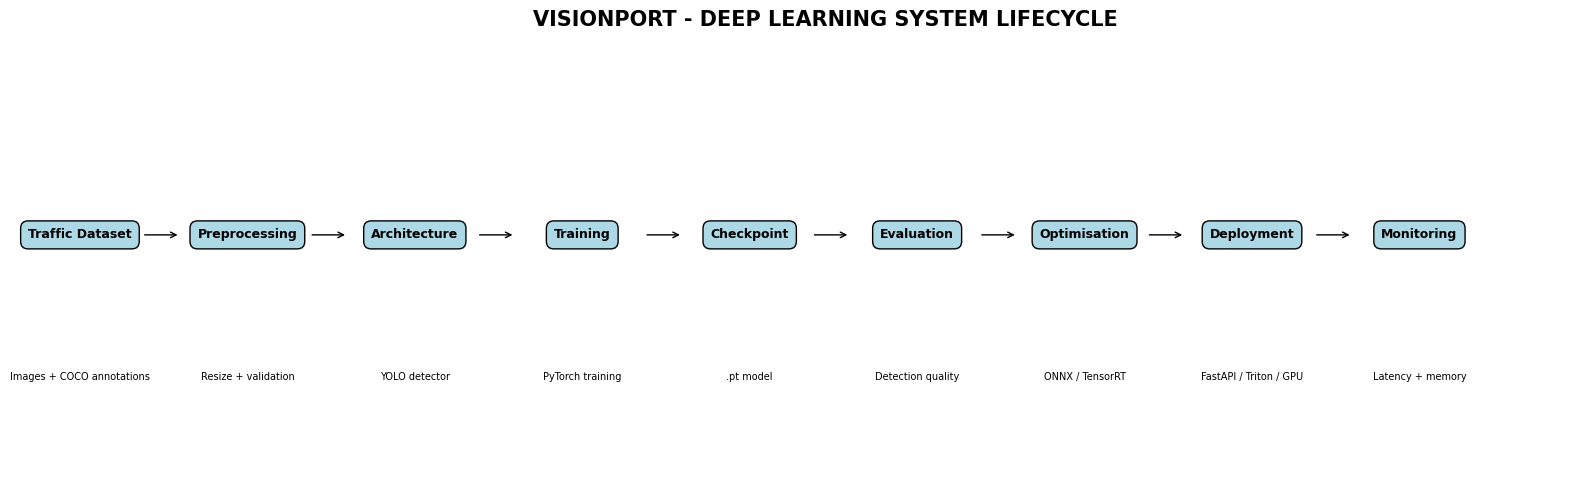

In [14]:
import matplotlib.pyplot as plt

stages = [
    "Traffic Dataset",
    "Preprocessing",
    "Architecture",
    "Training",
    "Checkpoint",
    "Evaluation",
    "Optimisation",
    "Deployment",
    "Monitoring"
]

descriptions = [
    "Images + COCO annotations",
    "Resize + validation",
    "YOLO detector",
    "PyTorch training",
    ".pt model",
    "Detection quality",
    "ONNX / TensorRT",
    "FastAPI / Triton / GPU",
    "Latency + memory"
]

fig, ax = plt.subplots(figsize=(16, 5))

ax.set_xlim(0, 9)
ax.set_ylim(0, 2)
ax.axis("off")

for i, (stage, description) in enumerate(
    zip(stages, descriptions)
):

    x = i + 0.05

    ax.text(
        x,
        1.1,
        stage,
        ha="center",
        va="center",
        fontsize=9,
        fontweight="bold",
        bbox=dict(
            boxstyle="round,pad=0.6",
            facecolor="lightblue",
            edgecolor="black"
        )
    )

    ax.text(
        x,
        0.45,
        description,
        ha="center",
        fontsize=7
    )

    if i < len(stages) - 1:

        ax.annotate(
            "",
            xy=(i + 0.65, 1.1),
            xytext=(i + 0.42, 1.1),
            arrowprops=dict(arrowstyle="->")
        )

plt.title(
    "VISIONPORT - DEEP LEARNING SYSTEM LIFECYCLE",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig("VisionPort_CO1_Lifecycle.png", dpi=200)
plt.show()

In [15]:
from pathlib import Path
import shutil

project_dirs = [
    "VisionPort/data/images",
    "VisionPort/data/annotations",
    "VisionPort/models",
    "VisionPort/api",
    "VisionPort/evaluation",
    "VisionPort/outputs",
    "VisionPort/config"
]

for directory in project_dirs:
    Path(directory).mkdir(parents=True, exist_ok=True)

# Preserve the pretrained checkpoint
checkpoint = Path(MODEL_NAME)

if checkpoint.exists():
    shutil.copy2(
        checkpoint,
        "VisionPort/models/yolov8n.pt"
    )

# Save the project architecture information
with open(
    "VisionPort/config/system_config.json",
    "w"
) as f:

    json.dump({
        "project": "VisionPort",
        "model": MODEL_NAME,
        "device": str(DEVICE),
        "input_size": 640,
        "confidence_threshold": 0.25,
        "classes": model.names
    }, f, indent=4)

print("VISIONPORT REPOSITORY STRUCTURE")

for path in Path("VisionPort").rglob("*"):
    print(path)

VISIONPORT REPOSITORY STRUCTURE
VisionPort/models
VisionPort/config
VisionPort/api
VisionPort/data
VisionPort/evaluation
VisionPort/outputs
VisionPort/models/yolov8n.pt
VisionPort/config/system_config.json
VisionPort/data/images
VisionPort/data/annotations
